**Cell 00 · Cell index**

- **01 · Intro & Python stack (lavaan / semTools / semPlot equivalents)**
- **02 · Setup & load data**
- **03 · Indicator blocks (theory)**
- **04 · Define indicator groups & collapse diagnosis by transmission**
- **05 · Harmonize direction (higher = more severity)**
- **06 · Method A — composite latent scores**
- **07 · Scale reliability (semTools-style)**
- **08 · CB-SEM model specification**
- **09 · Fit CB-SEM with semopy & lavaan-style fit summary**
- **10 · CB-SEM report & path diagram (matplotlib)**
- **11 · Visualizations — latents, structure, and transmission group**
- **12 · Export analysis table**
- **13 · PLS-SEM specification (smartPLS-style)**
- **14 · Fit PLS-SEM with seminr & bootstrap summary**
- **15 · PLS-SEM report & path diagram (matplotlib)**
- **16 · PLS-SEM visualizations — latents and transmission group**
- **17 · Export PLS-SEM results**


**Cell 01 · Intro**

We build **symptom_severity** (one composite from all symptoms) plus three **system-stress latents** (circulation stress, blood stress, bodily stress) from `synthetic_medical_symptoms_dataset.csv` using **Method A (composite scores)**: harmonize indicators, then take the **row mean** of z-scores in each block.

**Diagnosis (collapsed):** original five labels are mapped to **transmission mechanism**:
- **Contagious (Dx = 1):** COVID-19, Influenza, Pneumonia
- **Insect-borne (Dx = 0):** Dengue, Malaria

**CB-SEM** tests measurement + structural paths with Python packages mirroring the usual R workflow:

| R package | Role | Python equivalent in this notebook |
|-----------|------|-------------------------------------|
| **lavaan** | CB-SEM estimation, fit indices | **semopy** (`Model`, `fit`, `inspect(std_est=True)` ≈ `std.lv=TRUE`) |
| **semTools** | Reliability / scale diagnostics | **Cronbach’s α** on harmonized blocks |
| **semPlot** | Path diagrams | **matplotlib** path diagram (Cell 10) + bar/box/heatmap (Cell 11) |

**Structural model (no demographics):** circulation stress → blood stress → bodily stress → **symptom_severity** (sole endogenous outcome). Age and gender stay in the CSV but are **not** in the model.

**Estimation:** indicators and **symptom_severity** are treated as **continuous** (harmonized z-scores / composites). CB-SEM uses semopy **ML** (default **MLW**) on that analysis table — no separate DWLS/WLS or polychoric-weighted comparison.


In [43]:
# Cell 02 · Setup & load raw data
from __future__ import annotations

import importlib.util
import subprocess
import sys
from pathlib import Path

for pkg in ("pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "semopy", "seminr"):
    spec_name = "sklearn" if pkg == "scikit-learn" else pkg
    if importlib.util.find_spec(spec_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Circle, Rectangle
from scipy.stats import chi2 as chi2_dist
from semopy import Model
from semopy.stats import calc_stats
from sklearn.preprocessing import StandardScaler


# Path-diagram geometry: arrows stop at shape borders (not through labels)
LATENT_CIRCLE_R = 0.6
OUTCOME_BOX_HW, OUTCOME_BOX_HH = 0.9, 0.45
INDICATOR_BOX_HW, INDICATOR_BOX_HH = 0.45, 0.3
SHAPE_EDGE_PAD = 0.05


def _unit_vector(dx: float, dy: float) -> tuple[float, float]:
    length = (dx * dx + dy * dy) ** 0.5
    if length < 1e-9:
        return 0.0, 0.0
    return dx / length, dy / length


def _rect_border_t(half_w: float, half_h: float, ux: float, uy: float) -> float:
    if abs(ux) < 1e-9:
        return half_h
    if abs(uy) < 1e-9:
        return half_w
    return min(half_w / abs(ux), half_h / abs(uy))


def shape_border_point(
    cx: float,
    cy: float,
    toward_x: float,
    toward_y: float,
    *,
    kind: str,
) -> tuple[float, float]:
    """Point on the border of a node, on the ray from center toward (toward_x, toward_y)."""
    dx, dy = toward_x - cx, toward_y - cy
    ux, uy = _unit_vector(dx, dy)
    if kind == "circle":
        t = LATENT_CIRCLE_R + SHAPE_EDGE_PAD
    elif kind == "outcome_box":
        t = _rect_border_t(OUTCOME_BOX_HW, OUTCOME_BOX_HH, ux, uy) + SHAPE_EDGE_PAD
    elif kind == "indicator_box":
        t = _rect_border_t(INDICATOR_BOX_HW, INDICATOR_BOX_HH, ux, uy) + SHAPE_EDGE_PAD
    else:
        raise ValueError(f"Unknown node kind: {kind}")
    return cx + ux * t, cy + uy * t


def spillover_arc_rad(
    sx: float,
    sy: float,
    dx: float,
    dy: float,
    node_positions: dict[str, tuple[float, float]],
    latent_names: set[str],
    src: str,
    dst: str,
) -> float | None:
    """Curve around intermediate latents when a same-row path would cross through them."""
    if abs(sy - dy) > 0.08:
        return None
    xmin, xmax = min(sx, dx), max(sx, dx)
    for name, (bx, by) in node_positions.items():
        if name in (src, dst) or name not in latent_names:
            continue
        if abs(by - sy) > 0.08:
            continue
        if xmin + LATENT_CIRCLE_R + 0.05 < bx < xmax - LATENT_CIRCLE_R - 0.05:
            return -0.38
    return None


def draw_path_arrow(
    ax,
    sx: float,
    sy: float,
    dx: float,
    dy: float,
    label: str,
    *,
    src_kind: str,
    dst_kind: str,
    label_offset: float = 0.18,
    arc_rad: float | None = None,
) -> None:
    """Draw arrow from source node edge to destination node edge."""
    from matplotlib.patches import FancyArrowPatch

    x1, y1 = shape_border_point(sx, sy, dx, dy, kind=src_kind)
    x2, y2 = shape_border_point(dx, dy, sx, sy, kind=dst_kind)
    if arc_rad is not None:
        ax.add_patch(
            FancyArrowPatch(
                (x1, y1),
                (x2, y2),
                arrowstyle="-|>",
                mutation_scale=12,
                lw=1.4,
                color="#333333",
                connectionstyle=f"arc3,rad={arc_rad}",
                zorder=4,
            )
        )
        mx = (x1 + x2) / 2
        my = (y1 + y2) / 2 - arc_rad * abs(x2 - x1) * 0.2
        px, py = 0.0, label_offset
    else:
        ax.annotate(
            "",
            xy=(x2, y2),
            xytext=(x1, y1),
            arrowprops=dict(
                arrowstyle="-|>", color="#333333", lw=1.4, shrinkA=0, shrinkB=0, mutation_scale=12
            ),
            zorder=4,
        )
        mx, my = (x1 + x2) / 2, (y1 + y2) / 2
        ux, uy = _unit_vector(x2 - x1, y2 - y1)
        px, py = -uy * label_offset, ux * label_offset
    ax.text(
        mx + px,
        my + py,
        label,
        fontsize=8,
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9),
        zorder=6,
    )


def node_shape_kind(name: str, *, outcome_names: set[str]) -> str:
    if name in outcome_names:
        return "outcome_box"
    return "circle"



def rmsea_ci_90(chi2_val: float, dof: int, n: int) -> tuple[float, float]:
    if dof <= 0 or n <= 1:
        return float("nan"), float("nan")
    if chi2_val < dof:
        rmsea = 0.0
    else:
        rmsea = ((chi2_val / dof - 1) / (n - 1)) ** 0.5
    lam = max(chi2_val - dof, 0.0)
    lo = max(0.0, ((lam / dof) / (n - 1)) ** 0.5) if dof else 0.0
    hi = (((lam + chi2_dist.ppf(0.95, dof)) / dof - 1) / (n - 1)) ** 0.5 if dof else float("nan")
    if chi2_val < dof:
        lo = 0.0
    return lo, max(0.0, hi)


def cbsem_measurement_by_latent(
    inspection: pd.DataFrame,
    *,
    latent_names: set[str],
    indicator_names: set[str],
) -> dict[str, list[tuple[str, float]]]:
    """semopy lists loadings as indicator ~ factor (op '~'), not lavaan '=~'."""
    rows = inspection[
        (inspection["op"] == "~")
        & inspection["lval"].isin(indicator_names)
        & inspection["rval"].isin(latent_names)
    ]
    by_latent: dict[str, list[tuple[str, float]]] = {k: [] for k in latent_names}
    for _, row in rows.iterrows():
        est = pd.to_numeric(row["Est. Std"], errors="coerce")
        if pd.isna(est):
            continue
        by_latent[row["rval"]].append((row["lval"], float(est)))
    return by_latent


def cbsem_structural_results_table(
    inspection: pd.DataFrame,
    *,
    latent_names: set[str],
    outcome_names: set[str],
    indicator_names: set[str],
) -> pd.DataFrame:
    paths = inspection.loc[inspection["op"] == "~"].copy()
    is_loading = paths["lval"].isin(indicator_names) & paths["rval"].isin(latent_names)
    struct = paths.loc[~is_loading].copy()
    struct = struct.loc[
        struct["lval"].isin(latent_names | outcome_names) & struct["rval"].isin(latent_names)
    ]
    return pd.DataFrame(
        {
            "Predictor": struct["rval"].values,
            "Outcome": struct["lval"].values,
            "CB_SEM_Estimate": pd.to_numeric(struct["Est. Std"], errors="coerce").values,
            "CB_SEM_P_value": pd.to_numeric(struct["p-value"], errors="coerce").values,
        }
    )


def print_cbsem_model_report(
    model: Model,
    inspection: pd.DataFrame,
    fit_stats: pd.Series,
    *,
    latent_names: set[str],
    outcome_names: set[str],
    indicator_names: set[str],
) -> pd.DataFrame:
    cb_results = cbsem_structural_results_table(
        inspection,
        latent_names=latent_names,
        outcome_names=outcome_names,
        indicator_names=indicator_names,
    )
    chi2_val = float(fit_stats["chi2"])
    dof = int(fit_stats["DoF"])
    n = int(model.n_samples)
    rmsea = float(fit_stats["RMSEA"])
    lo, hi = rmsea_ci_90(chi2_val, dof, n)
    p_le_005 = float("nan")
    if rmsea > 0 and dof > 0:
        p_le_005 = float(1 - chi2_dist.cdf(chi2_val, dof))

    display_results = cb_results.copy()
    display_results["Predictor"] = display_results["Predictor"].map(lambda x: LATENT_STRESS_LABELS.get(x, x))
    display_results["Outcome"] = display_results["Outcome"].map(lambda x: LATENT_STRESS_LABELS.get(x, x))
    print("CB-SEM Structural Results:")
    print("> print(cb_results)")
    print(display_results.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    print()
    print("User Model versus Baseline Model:")
    print(f"{'':44} Estimate")
    print(f"{'Comparative Fit Index (CFI)':44} {float(fit_stats['CFI']):.3f}")
    print(f"{'Tucker-Lewis Index (TLI)':44} {float(fit_stats['TLI']):.3f}")
    print(f"{'Robust CFI/TLI':44} NA")
    print()
    print("Root Mean Square Error of Approximation:")
    print(f"{'RMSEA':44} {rmsea:.3f}")
    print(f"{'90 Percent confidence interval lower':44} {lo:.3f}")
    print(f"{'90 Percent confidence interval upper':44} {hi:.3f}")
    print(f"{'P-value H_0: RMSEA <= 0.050':44} {p_le_005:.3f}" if pd.notna(p_le_005) else f"{'P-value H_0: RMSEA <= 0.050':44} NA")
    print(f"{'P-value H_0: RMSEA >= 0.080':44} NA")
    print(f"{'Robust RMSEA':44} NA")
    return cb_results


def pls_structural_results_table(boot_paths: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for label in boot_paths.index:
        if "->" not in str(label):
            continue
        src, tgt = str(label).split("->", 1)
        rows.append(
            {
                "Predictor": src.strip(),
                "Outcome": tgt.strip(),
                "PLS_Estimate": float(boot_paths.loc[label, "Original Est."]),
                "PLS_P_value": float(boot_paths.loc[label, "Bootstrap P Val"]),
            }
        )
    return pd.DataFrame(rows)


def print_pls_model_report(pls_model, boot_summary, boot_paths: pd.DataFrame) -> pd.DataFrame:
    pls_results = pls_structural_results_table(boot_paths)
    r2_nm = pls_model.r_squared
    r2 = pd.DataFrame(r2_nm.values, index=list(r2_nm.rows), columns=list(r2_nm.cols))

    display_pls = pls_results.copy()
    display_pls["Predictor"] = display_pls["Predictor"].map(lambda x: LATENT_STRESS_LABELS.get(x, x))
    display_pls["Outcome"] = display_pls["Outcome"].map(lambda x: LATENT_STRESS_LABELS.get(x, x))
    print("PLS-SEM Structural Results:")
    print("> print(pls_results)")
    print(display_pls.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    print()
    print("Model estimation summary:")
    print(f"{'Iterations to converge':44} {pls_model.iterations}")
    print(f"{'Bootstrap replications':44} {boot_summary.nboot}")
    print()
    print("Endogenous composite R-squared:")
    if "Rsq" in r2.index:
        for col in r2.columns:
            print(f"  {col}: R² = {float(r2.loc['Rsq', col]):.3f}  Adj R² = {float(r2.loc['AdjRsq', col]):.3f}")
    print()
    print("Note: PLS-SEM does not produce lavaan-style CFI/TLI/RMSEA; use bootstrapped path p-values above.")
    return pls_results

NOTEBOOK_DIR = Path.cwd().resolve()
CSV_PATH = NOTEBOOK_DIR / "synthetic_medical_symptoms_dataset.csv"
if not CSV_PATH.exists():
    CSV_PATH = NOTEBOOK_DIR.parent / "Respiratory Disesase Diagnosis" / "synthetic_medical_symptoms_dataset.csv"

OUTPUT_DIR = NOTEBOOK_DIR / "compiled"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(CSV_PATH)
print(f"Loaded: {CSV_PATH}")
print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head(3))


Loaded: C:\Users\tnewman\Documents\DDDM\Respiratory Disesase Diagnosis\synthetic_medical_symptoms_dataset.csv
Shape: 3,000 rows × 24 columns


,age,gender,fever,cough,fatigue,headache,muscle_pain,nausea,vomiting,diarrhea,...,diastolic_bp,heart_rate,temperature_c,oxygen_saturation,wbc_count,hemoglobin,platelet_count,crp_level,glucose_level,diagnosis
0,52,Female,1,0,2,0,0,3,0,3,...,68.0,79.0,36.2,99.0,5.32,13.47,335.0,3.95,119.0,Dengue
1,15,Male,0,0,1,0,1,0,1,0,...,72.0,79.0,37.6,97.0,10.31,14.73,273.0,18.03,104.0,Dengue
2,72,Female,0,2,2,0,2,3,1,1,...,76.0,70.0,37.1,94.0,7.03,11.10,307.0,22.77,120.0,Influenza


**Cell 03 · Indicator blocks & symptom severity**

```mermaid
flowchart LR
  Sev[Observed: symptom_severity\ncomposite of all symptoms]
  CircStress[Latent: Circulation Stress]
  BloodStress[Latent: Blood Stress]
  BodStress[Latent: Bodily Stress]
  CircStress --> BP and HR
  BloodStress --> WBC Hgb Plt CRP glucose
  BodStress --> temp and SpO2
  CircStress --> BloodStress --> BodStress --> Sev
```

| Construct | Role | Indicators (this CSV) |
|-----------|------|------------------------|
| **symptom_severity** | Single **Method A** composite (mean of harmonized symptom z-scores) | All 11 symptom columns (0–3) |
| **Circulation stress** | Latent **CircStress** | `systolic_bp`, `diastolic_bp`, `heart_rate` |
| **Blood stress** | Latent **BloodStress** | `wbc_count`, `hemoglobin`, `platelet_count`, `crp_level`, `glucose_level` |
| **Bodily stress** | Latent **BodStress** | `temperature_c`, `oxygen_saturation` |

`age` and `gender` are not in the SEM. **transmission_group** may appear in descriptive plots only; it is not a structural outcome.

There are no additional float64 clinical columns in this dataset beyond the groups above.


In [44]:
# Cell 04 · Define blocks, symptom severity composite prep & Dx coding
SYMPTOM_COLS = [
    "fever", "cough", "fatigue", "headache", "muscle_pain", "nausea",
    "vomiting", "diarrhea", "skin_rash", "loss_smell", "loss_taste",
]
CIRCULATION_COLS = ["systolic_bp", "diastolic_bp", "heart_rate"]
BLOOD_TEST_COLS = [
    "wbc_count", "hemoglobin", "platelet_count", "crp_level", "glucose_level",
]
BODILY_STRESS_COLS = ["temperature_c", "oxygen_saturation"]

# Higher harmonized value = greater severity (lower SpO2 and Hgb are worse)
REVERSE_AFTER_Z = {"oxygen_saturation", "hemoglobin"}

SEVERITY_COL = "symptom_severity"

CIRC_STRESS_LAT = "CircStress"
BLOOD_STRESS_LAT = "BloodStress"
BOD_STRESS_LAT = "BodStress"
CBSEM_LATENT_NAMES = {CIRC_STRESS_LAT, BLOOD_STRESS_LAT, BOD_STRESS_LAT}
SEM_INDICATOR_NAMES = set(CIRCULATION_COLS + BLOOD_TEST_COLS + BODILY_STRESS_COLS)

# Human-readable names (tables); diagrams use LATENT_NODE_LABELS
LATENT_STRESS_LABELS = {
    CIRC_STRESS_LAT: "Circulation Stress",
    BLOOD_STRESS_LAT: "Blood Stress",
    BOD_STRESS_LAT: "Bodily Stress",
}
LATENT_NODE_LABELS = {
    CIRC_STRESS_LAT: "Circulation\nStress",
    BLOOD_STRESS_LAT: "Blood\nStress",
    BOD_STRESS_LAT: "Bodily\nStress",
}


LATENT_ROW_Y = 5.0
OUTCOME_ROW_Y = 8.75
INDICATOR_ROW_Y = 2.45


def system_stress_diagram_positions(outcome_node: str, outcome_x: float = 5.0) -> dict[str, tuple[float, float]]:
    """Outcome (symptom severity) on top; system-stress latents in a row below."""
    return {
        CIRC_STRESS_LAT: (2.0, LATENT_ROW_Y),
        BLOOD_STRESS_LAT: (5.0, LATENT_ROW_Y),
        BOD_STRESS_LAT: (8.0, LATENT_ROW_Y),
        outcome_node: (outcome_x, OUTCOME_ROW_Y),
    }


OUTCOME_NODE_LABELS = {
    SEVERITY_COL: "Symptom\nseverity",
    "SevGrp": "Symptom\nseverity",
}

LATENT_BLOCKS = {
    "circulation_stress": CIRCULATION_COLS,
    "blood_stress": BLOOD_TEST_COLS,
    "bodily_stress": BODILY_STRESS_COLS,
}

TRANSMISSION_BY_DIAGNOSIS = {
    "COVID-19": "contagious",
    "Influenza": "contagious",
    "Pneumonia": "contagious",
    "Dengue": "insect_borne",
    "Malaria": "insect_borne",
}

df_analysis = df_raw.copy()
df_analysis["transmission_group"] = df_analysis["diagnosis"].map(TRANSMISSION_BY_DIAGNOSIS)
if df_analysis["transmission_group"].isna().any():
    unmapped = df_analysis.loc[df_analysis["transmission_group"].isna(), "diagnosis"].unique()
    raise ValueError(f"Unmapped diagnosis labels: {unmapped}")

for name, cols in LATENT_BLOCKS.items():
    missing = [c for c in cols if c not in df_analysis.columns]
    if missing:
        raise ValueError(f"{name}: missing columns {missing}")

blocks_table = [{"construct": k, "n_indicators": len(v), "indicators": ", ".join(v)} for k, v in LATENT_BLOCKS.items()]
blocks_table.insert(
    0,
    {
        "construct": SEVERITY_COL,
        "n_indicators": len(SYMPTOM_COLS),
        "indicators": "composite (row mean of harmonized symptom z-scores)",
    },
)
display(pd.DataFrame(blocks_table))

print("Diagnosis → transmission group:")
display(
    df_analysis.groupby(["transmission_group", "diagnosis"], as_index=False)
    .size()
    .rename(columns={"size": "n"})
    .sort_values(["transmission_group", "diagnosis"])
)
print("\nTransmission groups (descriptive only, not a structural outcome):")
print(df_analysis["transmission_group"].value_counts().to_string())


,construct,n_indicators,indicators
0,symptom_severity,11,composite (row mean of harmonized symptom z-sc...
1,circulation_stress,3,"systolic_bp, diastolic_bp, heart_rate"
2,blood_stress,5,"wbc_count, hemoglobin, platelet_count, crp_lev..."
3,bodily_stress,2,"temperature_c, oxygen_saturation"


Diagnosis → transmission group:


,transmission_group,diagnosis,n
0,contagious,COVID-19,711
1,contagious,Influenza,748
2,contagious,Pneumonia,438
3,insect_borne,Dengue,639
4,insect_borne,Malaria,464



Transmission groups (descriptive only, not a structural outcome):
transmission_group
contagious      1897
insect_borne    1103


In [45]:
# Cell 05 · Harmonize direction (higher = more severity)

def zscore_harmonized(frame: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    out = frame[columns].astype(float).copy()
    z = pd.DataFrame(StandardScaler().fit_transform(out), columns=columns, index=out.index)
    for col in columns:
        if col in REVERSE_AFTER_Z:
            z[col] = -z[col]
    return z


z_symptoms = zscore_harmonized(df_analysis, SYMPTOM_COLS)
z_circulation = zscore_harmonized(df_analysis, CIRCULATION_COLS)
z_blood = zscore_harmonized(df_analysis, BLOOD_TEST_COLS)
z_bodily = zscore_harmonized(df_analysis, BODILY_STRESS_COLS)

print("Higher values = more severity on every harmonized indicator.")
display(z_circulation.describe().T[["mean", "std", "min", "max"]])


Higher values = more severity on every harmonized indicator.


,mean,std,min,max
systolic_bp,1.006602e-16,1.000167,-4.219390,3.194727
diastolic_bp,-7.105427e-18,1.000167,-3.498508,4.316327
heart_rate,-4.500104e-17,1.000167,-3.081429,3.441285


**Cell 06 · Method A — composite latent scores**

1. Harmonized z-scores within each block.
2. **Latent score = row-wise mean** of those z-scores.
3. Re-standardize the composite to mean 0, SD 1.


In [46]:
# Cell 06 · Method A — symptom severity + latent composite scores

def composite_latent(z_block: pd.DataFrame) -> pd.Series:
    s = z_block.mean(axis=1)
    return (s - s.mean()) / s.std(ddof=0)


df_analysis[SEVERITY_COL] = composite_latent(z_symptoms)

df_latent = df_analysis[["diagnosis", "transmission_group", SEVERITY_COL]].copy()
df_latent["circulation_stress"] = composite_latent(z_circulation)
df_latent["blood_stress"] = composite_latent(z_blood)
df_latent["bodily_stress"] = composite_latent(z_bodily)

display(df_latent.describe().T)
display(df_latent.head())


,count,mean,std,min,25%,50%,75%,max
symptom_severity,3000.0,-2.486900e-17,1.000167,-3.077633,-0.595082,-0.019602,0.788041,3.331285
circulation_stress,3000.0,1.421085e-17,1.000167,-3.589999,-0.678038,-0.021317,0.686500,3.850722
blood_stress,3000.0,4.736952e-18,1.000167,-3.824868,-0.653568,-0.045203,0.654275,4.048341
bodily_stress,3000.0,7.105427e-18,1.000167,-3.400086,-0.666093,-0.019429,0.666565,3.892260


,diagnosis,transmission_group,symptom_severity,circulation_stress,blood_stress,bodily_stress
0,Dengue,insect_borne,-0.033971,-1.627152,0.222218,-1.299062
1,Dengue,insect_borne,-1.957232,-0.286962,1.080731,0.096404
2,Influenza,contagious,0.813105,-0.811918,2.348393,0.531167
3,COVID-19,contagious,-0.013896,0.546859,-0.281746,-0.545369
4,Dengue,insect_borne,-1.134793,-0.246420,1.943084,-1.310801


**Cell 07 · Scale reliability (semTools-style)**

Cronbach’s α on each harmonized block checks internal consistency before SEM (similar to **semTools** reliability routines).


In [47]:
# Cell 07 · Cronbach's alpha per block

def cronbach_alpha(z_block: pd.DataFrame) -> float:
    k = z_block.shape[1]
    item_vars = z_block.var(axis=0, ddof=1)
    total = z_block.sum(axis=1)
    total_var = total.var(ddof=1)
    if total_var == 0:
        return float("nan")
    return float(k / (k - 1) * (1 - item_vars.sum() / total_var))


reliability = pd.DataFrame(
    {
        "construct": ["symptom_scale (for severity composite)", *list(LATENT_BLOCKS.keys())],
        "n_items": [len(SYMPTOM_COLS), *[len(v) for v in LATENT_BLOCKS.values()]],
        "cronbach_alpha": [
            cronbach_alpha(z_symptoms),
            cronbach_alpha(z_circulation),
            cronbach_alpha(z_blood),
            cronbach_alpha(z_bodily),
        ],
    }
)
display(reliability)


,construct,n_items,cronbach_alpha
0,symptom_scale (for severity composite),11,-0.006952
1,circulation_stress,3,0.021105
2,blood_stress,5,0.005213
3,bodily_stress,2,-0.004016


**Cell 08 · CB-SEM specification**

- **Measurement:** **CircStress**, **BloodStress**, **BodStress** load on circulation, blood-test, and bodily-stress indicators.
- **Structural:** Circulation stress → blood stress → bodily stress → **symptom_severity** (observed composite).

Harmonized **z-scores** feed the three latent blocks; **symptom_severity** enters as a continuous observed endogenous variable.


In [48]:
# Cell 09 · Prepare data & fit CB-SEM

sem_df = pd.concat([z_circulation, z_blood, z_bodily], axis=1)
sem_df[SEVERITY_COL] = df_analysis[SEVERITY_COL].astype(float)

circ_ind = " + ".join(CIRCULATION_COLS)
blood_ind = " + ".join(BLOOD_TEST_COLS)
bod_ind = " + ".join(BODILY_STRESS_COLS)

CB_SEM_MODEL = f"""
{CIRC_STRESS_LAT} =~ {circ_ind}
{BLOOD_STRESS_LAT} =~ {blood_ind}
{BOD_STRESS_LAT} =~ {bod_ind}
{BLOOD_STRESS_LAT} ~ {CIRC_STRESS_LAT}
{BOD_STRESS_LAT} ~ {CIRC_STRESS_LAT} + {BLOOD_STRESS_LAT}
{SEVERITY_COL} ~ {CIRC_STRESS_LAT} + {BLOOD_STRESS_LAT} + {BOD_STRESS_LAT}
"""

print(CB_SEM_MODEL)
sem_fit = Model(CB_SEM_MODEL)
sem_result = sem_fit.fit(sem_df)
print(sem_result)



CircStress =~ systolic_bp + diastolic_bp + heart_rate
BloodStress =~ wbc_count + hemoglobin + platelet_count + crp_level + glucose_level
BodStress =~ temperature_c + oxygen_saturation
BloodStress ~ CircStress
BodStress ~ CircStress + BloodStress
symptom_severity ~ CircStress + BloodStress + BodStress

Name of objective: MLW
Optimization method: SLSQP
Optimization successful.
Optimization terminated successfully
Objective value: 0.016
Number of iterations: 12
Params: 0.022 0.023 -0.023 -0.098 0.085 -0.159 0.004 0.021 0.071 0.014 0.013 -0.105 -0.033 0.317 0.275 0.280 0.998 1.000 0.992 1.000 1.000 1.000 0.997 0.996 0.720 0.723 0.683


In [49]:
# Cell 09b · Prepare CB-SEM results (full report prints in Cell 10)

fit_stats = calc_stats(sem_fit).iloc[0]

struct = sem_fit.inspect(std_est=True)
struct_paths = struct[struct["op"] == "~"].copy()
SEM_OUTCOME_NAMES = {SEVERITY_COL}
struct_paths = struct_paths[
    (struct_paths["lval"].isin(SEM_OUTCOME_NAMES) & struct_paths["rval"].isin(CBSEM_LATENT_NAMES))
    | (struct_paths["lval"].isin(CBSEM_LATENT_NAMES) & struct_paths["rval"].isin(CBSEM_LATENT_NAMES))
].copy()

print("Standardized structural paths (~) — preview (full table in Cell 10):")
display(struct_paths)

print("\nAssociation check: Method A constructs vs symptom_severity:")
for col in [c for c in df_latent.columns if c.endswith("_stress")]:
    r_sev = df_latent[[col, SEVERITY_COL]].corr(numeric_only=True).iloc[0, 1]
    print(f"  {col}: r vs severity={r_sev:.4f}")


Standardized structural paths (~) — preview (full table in Cell 10):


,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value
0,BloodStress,~,CircStress,0.020610,0.019392,0.546812,0.037691,0.969934
1,BodStress,~,CircStress,0.071277,0.071751,1.879727,0.037919,0.969753
2,BodStress,~,BloodStress,0.013791,0.014754,0.071081,0.194013,0.846166
13,symptom_severity,~,CircStress,0.013147,0.006962,0.653047,0.020132,0.983938
14,symptom_severity,~,BloodStress,-0.105092,-0.059142,0.223685,-0.469822,0.638482
15,symptom_severity,~,BodStress,-0.033144,-0.017434,7.695452,-0.004307,0.996564



Association check: Method A constructs vs symptom_severity:
  circulation_stress: r vs severity=0.0098
  blood_stress: r vs severity=-0.0309
  bodily_stress: r vs severity=-0.0018


CB-SEM Structural Results:
> print(cb_results)
         Predictor          Outcome  CB_SEM_Estimate  CB_SEM_P_value
Circulation Stress     Blood Stress            0.019           0.970
Circulation Stress    Bodily Stress            0.072           0.970
      Blood Stress    Bodily Stress            0.015           0.846
Circulation Stress symptom_severity            0.007           0.984
      Blood Stress symptom_severity           -0.059           0.638
     Bodily Stress symptom_severity           -0.017           0.997

User Model versus Baseline Model:
                                             Estimate
Comparative Fit Index (CFI)                  0.184
Tucker-Lewis Index (TLI)                     -0.150
Robust CFI/TLI                               NA

Root Mean Square Error of Approximation:
RMSEA                                        0.009
90 Percent confidence interval lower         0.009
90 Percent confidence interval upper         0.015
P-value H_0: RMSEA <= 0.050        

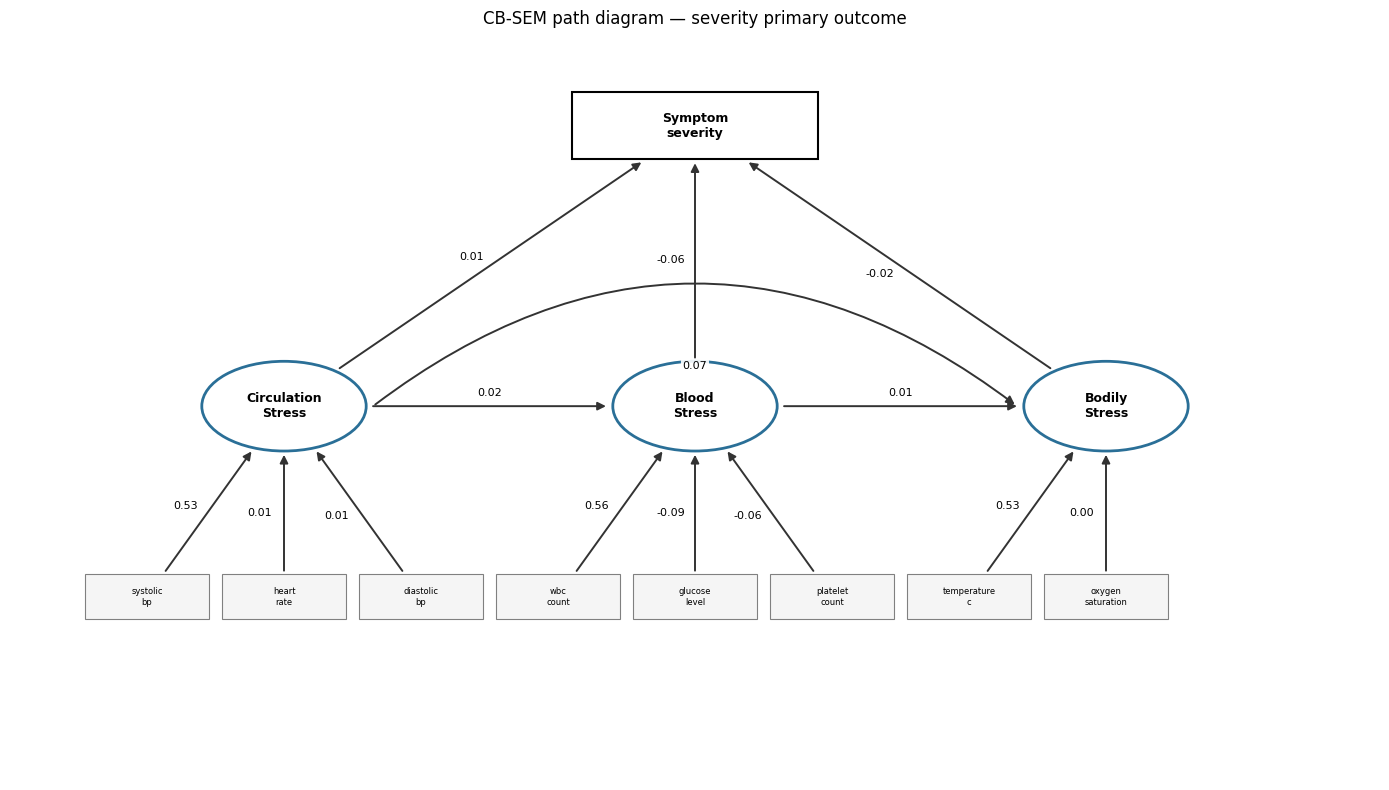

Saved C:\Users\tnewman\Documents\DDDM\Respiratory Disesase Diagnosis\compiled\cbsem_path_diagram.png


In [50]:
# Cell 10 · CB-SEM model report & path diagram (matplotlib — semPlot-style)

cb_results = print_cbsem_model_report(
    sem_fit,
    struct,
    fit_stats,
    latent_names=CBSEM_LATENT_NAMES,
    outcome_names=SEM_OUTCOME_NAMES,
    indicator_names=SEM_INDICATOR_NAMES,
)

OUTCOME_NODES = {SEVERITY_COL}


def plot_cbsem_path_diagram(
    inspection: pd.DataFrame,
    struct_paths: pd.DataFrame,
    save_path: Path,
    *,
    top_indicators: int = 3,
) -> None:
    """Draw structural paths + top standardized loadings (semopy: indicator ~ latent)."""
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis("off")

    latent_pos = system_stress_diagram_positions(SEVERITY_COL)

    for name, (x, y) in latent_pos.items():
        if name in OUTCOME_NODES:
            ax.add_patch(
                Rectangle(
                    (x - OUTCOME_BOX_HW, y - OUTCOME_BOX_HH),
                    2 * OUTCOME_BOX_HW,
                    2 * OUTCOME_BOX_HH,
                    fill=False,
                    ec="black",
                    lw=1.5,
                    zorder=3,
                )
            )
        else:
            ax.add_patch(Circle((x, y), LATENT_CIRCLE_R, fill=False, ec="#2a6f97", lw=2, zorder=3))
        label = OUTCOME_NODE_LABELS.get(name, LATENT_NODE_LABELS.get(name, name.replace("_", "\n")))
        ax.text(x, y, label, ha="center", va="center", fontsize=9, fontweight="bold", zorder=4)

    for _, row in struct_paths.iterrows():
        src, dst = row["rval"], row["lval"]
        if src not in latent_pos or dst not in latent_pos:
            continue
        x1, y1 = latent_pos[src]
        x2, y2 = latent_pos[dst]
        arc = spillover_arc_rad(
            x1, y1, x2, y2, latent_pos, CBSEM_LATENT_NAMES, src, dst
        )
        draw_path_arrow(
            ax,
            x1,
            y1,
            x2,
            y2,
            f"{row['Est. Std']:.2f}",
            src_kind=node_shape_kind(src, outcome_names=OUTCOME_NODES),
            dst_kind=node_shape_kind(dst, outcome_names=OUTCOME_NODES),
            arc_rad=arc,
        )

    by_latent = cbsem_measurement_by_latent(
        inspection,
        latent_names=CBSEM_LATENT_NAMES,
        indicator_names=SEM_INDICATOR_NAMES,
    )

    for lat in CBSEM_LATENT_NAMES:
        lx, ly = latent_pos[lat]
        picks = sorted(by_latent.get(lat, []), key=lambda t: abs(t[1]), reverse=True)[:top_indicators]
        for i, (ind, est) in enumerate(picks):
            ix = lx - 1.0 + i * 1.0
            iy = INDICATOR_ROW_Y
            ax.add_patch(
                Rectangle(
                    (ix - INDICATOR_BOX_HW, iy - INDICATOR_BOX_HH),
                    2 * INDICATOR_BOX_HW,
                    2 * INDICATOR_BOX_HH,
                    fc="#f5f5f5",
                    ec="gray",
                    lw=0.8,
                    zorder=1,
                )
            )
            ax.text(ix, iy, ind.replace("_", "\n"), ha="center", va="center", fontsize=6, zorder=3)
            draw_path_arrow(
                ax,
                ix,
                iy,
                lx,
                ly,
                f"{est:.2f}",
                src_kind="indicator_box",
                dst_kind="circle",
            )

    ax.set_title("CB-SEM path diagram — severity primary outcome")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


path_png = OUTPUT_DIR / "cbsem_path_diagram.png"
plot_cbsem_path_diagram(struct, struct_paths, path_png)
print(f"Saved {path_png}")


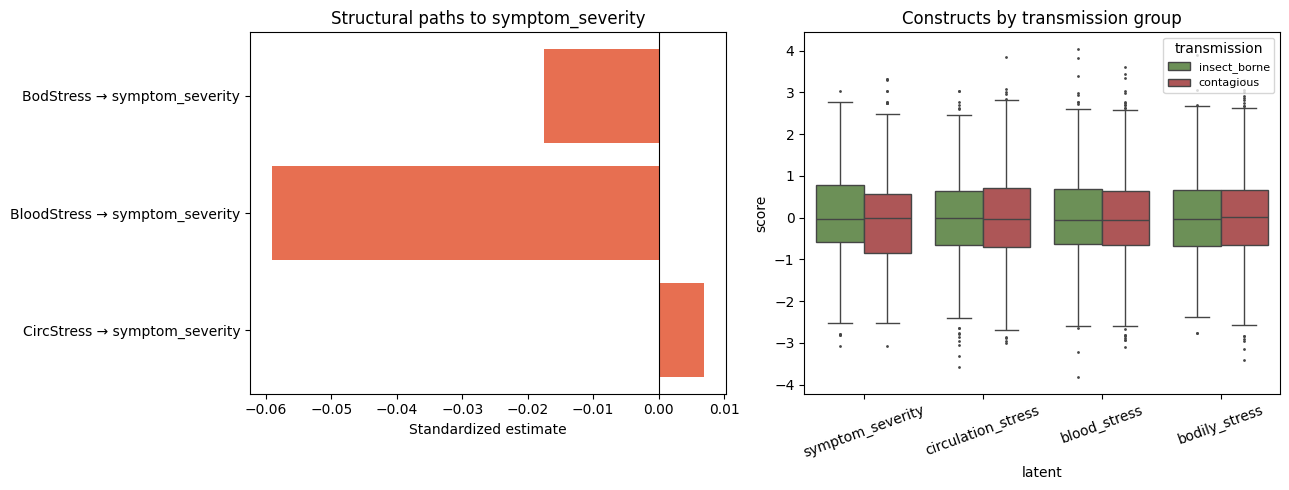

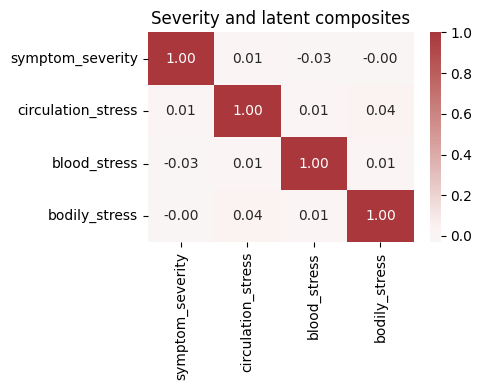

In [51]:
# Cell 11 · Visualizations — latents, structure, and transmission group

# --- 1) Standardized structural coefficients
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

reg = struct_paths.copy()
struct_sev = struct_paths[struct_paths["lval"] == SEVERITY_COL].copy()
reg = struct_sev.copy()
reg["label"] = reg["rval"] + " → " + reg["lval"]
colors = ["#e76f51"] * len(reg)
axes[0].barh(reg["label"], reg["Est. Std"], color=colors)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_xlabel("Standardized estimate")
axes[0].set_title("Structural paths to symptom_severity")

# --- 2) Method A composites by transmission group
plot_df = df_latent.copy()
order = ["insect_borne", "contagious"]
melt = plot_df.melt(
    id_vars="transmission_group",
    value_vars=[
        SEVERITY_COL,
        "circulation_stress",
        "blood_stress",
        "bodily_stress",
    ],
    var_name="latent",
    value_name="score",
)
sns.boxplot(
    data=melt,
    x="latent",
    y="score",
    hue="transmission_group",
    hue_order=order,
    ax=axes[1],
    fliersize=1,
    palette={"insect_borne": "#6a994e", "contagious": "#bc4749"},
)
axes[1].set_title("Constructs by transmission group")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(title="transmission", loc="best", fontsize=8)

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "latent_severity_visualization.png", dpi=150, bbox_inches="tight")
plt.show()

# --- 3) Correlation among symptom severity and Method A latents
corr_df = df_latent[[SEVERITY_COL, "circulation_stress", "blood_stress", "bodily_stress"]].copy()
latent_corr = corr_df.corr(numeric_only=True)
fig2, ax2 = plt.subplots(figsize=(5, 4))
sns.heatmap(latent_corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax2)
ax2.set_title("Severity and latent composites")
fig2.tight_layout()
plt.savefig(OUTPUT_DIR / "latent_severity_correlation.png", dpi=150)
plt.show()


In [52]:
# Cell 12 · Export analysis table
export = df_analysis.copy()
for col in df_latent.columns:
    if col.endswith("_stress"):
        export[col] = df_latent[col]

export_path = OUTPUT_DIR / "sem_analysis_table.csv"
export.to_csv(export_path, index=False)
fit_stats.to_frame(name="Value").to_csv(OUTPUT_DIR / "cbsem_fit_statistics.csv")
struct_paths.to_csv(OUTPUT_DIR / "cbsem_structural_paths_std.csv", index=False)
cb_results.to_csv(OUTPUT_DIR / "cbsem_structural_results.csv", index=False)
reliability.to_csv(OUTPUT_DIR / "scale_reliability.csv", index=False)

print(f"Wrote {export_path}")
print("Also: cbsem_fit_statistics.csv, cbsem_structural_paths_std.csv, scale_reliability.csv")


Wrote C:\Users\tnewman\Documents\DDDM\Respiratory Disesase Diagnosis\compiled\sem_analysis_table.csv
Also: cbsem_fit_statistics.csv, cbsem_structural_paths_std.csv, scale_reliability.csv


**Cell 13 · PLS-SEM specification**

**PLS-SEM** (partial least squares) estimates composite latent scores and path coefficients with a prediction-oriented algorithm — common in **smartPLS** workflows.

| R / software | Python in this notebook |
|--------------|-------------------------|
| smartPLS / seminr | **seminr** (`estimate_pls`, `bootstrap_model`, `summarize`) |

Same measurement blocks and structural paths as CB-SEM (Cell 08–09):
- **Composites (Mode A):** **CircStress**, **BloodStress**, **BodStress**; **SevGrp** = single indicator `symptom_severity`
- **Structure:** circulation stress → blood stress → bodily stress → **SevGrp**

We use **composite** (not PLSc reflective) mode to avoid disattenuation issues on weak blocks.


In [53]:
# Cell 14 · Fit PLS-SEM (seminr) & bootstrap summary
from seminr import (
    bootstrap_model,
    composite,
    estimate_pls,
    paths,
    relationships,
    single_item,
    summarize,
)

pls_df = pd.concat([z_circulation, z_blood, z_bodily], axis=1)
pls_df[SEVERITY_COL] = df_analysis[SEVERITY_COL].astype(float)
PLS_MEASUREMENT = [
    composite(CIRC_STRESS_LAT, CIRCULATION_COLS),
    composite(BLOOD_STRESS_LAT, BLOOD_TEST_COLS),
    composite(BOD_STRESS_LAT, BODILY_STRESS_COLS),
    composite("SevGrp", single_item(SEVERITY_COL)),
]
PLS_STRUCTURE = relationships(
    paths(CIRC_STRESS_LAT, BLOOD_STRESS_LAT),
    paths(CIRC_STRESS_LAT, BOD_STRESS_LAT),
    paths(BLOOD_STRESS_LAT, BOD_STRESS_LAT),
    paths([CIRC_STRESS_LAT, BLOOD_STRESS_LAT, BOD_STRESS_LAT], "SevGrp"),
)

pls_fit = estimate_pls(pls_df, PLS_MEASUREMENT, PLS_STRUCTURE)
pls_boot = bootstrap_model(pls_fit, nboot=500, cores=1)
pls_boot_summary = summarize(pls_boot)


def named_matrix_to_frame(nm) -> pd.DataFrame:
    return pd.DataFrame(nm.values, index=list(nm.rows), columns=list(nm.cols))


def pls_structural_paths(path_coef, endogenous: set[str]) -> pd.DataFrame:
    """Convert seminr path_coef (target row, source col) to CB-SEM-style paths."""
    rows = []
    for tgt in path_coef.rows:
        if tgt not in endogenous:
            continue
        for src in path_coef.cols:
            est = float(path_coef.get(tgt, src))
            if abs(est) < 1e-8:
                continue
            rows.append({"lval": tgt, "rval": src, "Est. Std": est, "op": "~"})
    return pd.DataFrame(rows)


def pls_boot_paths_table(boot_summary) -> pd.DataFrame:
    nm = boot_summary.bootstrapped_paths
    return pd.DataFrame(nm.values, index=list(nm.rows), columns=list(nm.cols))


pls_boot_paths = pls_boot_paths_table(pls_boot_summary)
pls_struct_paths = pls_structural_paths(
    pls_fit.path_coef, endogenous={BLOOD_STRESS_LAT, BOD_STRESS_LAT, 'SevGrp'}
)

display(pls_boot_paths.head(12))
display(named_matrix_to_frame(pls_fit.outer_loadings).iloc[:6, :4])


,Original Est.,Bootstrap Mean,Bootstrap SD,T Stat.,2.5% CI,97.5% CI,Bootstrap P Val
CircStress -> BloodStress,0.020084,0.020483,0.044635,0.449964,-0.073897,0.088623,0.608
CircStress -> BodStress,0.078076,0.079209,0.031442,2.483154,-0.037255,0.119479,0.064
CircStress -> SevGrp,0.009272,0.008972,0.022872,0.405383,-0.036054,0.053573,0.648
BloodStress -> BodStress,-0.003726,0.000239,0.038816,-0.096002,-0.069399,0.072646,0.968
BloodStress -> SevGrp,-0.057166,-0.047726,0.040324,-1.417684,-0.100565,0.061526,0.240
BodStress -> SevGrp,0.006012,0.003760,0.020664,0.290967,-0.035757,0.044650,0.872


,CircStress,BloodStress,BodStress,SevGrp
systolic_bp,0.841986,0.000000,0.0,0.0
diastolic_bp,0.311280,-0.000000,0.0,-0.0
heart_rate,0.452941,0.000000,0.0,0.0
wbc_count,0.000000,0.557126,-0.0,-0.0
hemoglobin,0.000000,0.641888,0.0,-0.0
platelet_count,0.000000,0.132377,0.0,-0.0


PLS-SEM Structural Results:
> print(pls_results)
         Predictor       Outcome  PLS_Estimate  PLS_P_value
Circulation Stress  Blood Stress         0.020        0.608
Circulation Stress Bodily Stress         0.078        0.064
Circulation Stress        SevGrp         0.009        0.648
      Blood Stress Bodily Stress        -0.004        0.968
      Blood Stress        SevGrp        -0.057        0.240
     Bodily Stress        SevGrp         0.006        0.872

Model estimation summary:
Iterations to converge                       27
Bootstrap replications                       500

Endogenous composite R-squared:
  BloodStress: R² = 0.000  Adj R² = 0.000
  BodStress: R² = 0.006  Adj R² = 0.005
  SevGrp: R² = 0.003  Adj R² = 0.002

Note: PLS-SEM does not produce lavaan-style CFI/TLI/RMSEA; use bootstrapped path p-values above.


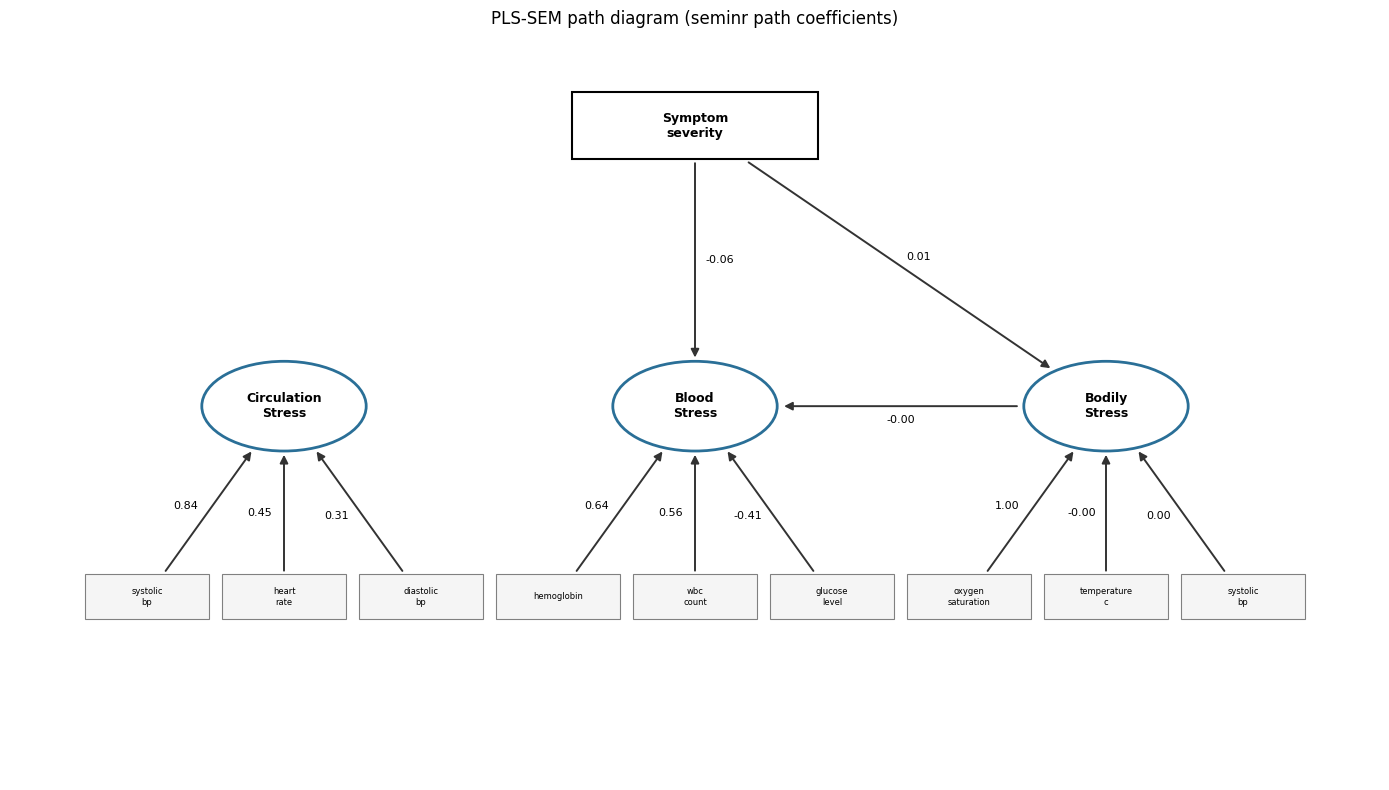

Saved C:\Users\tnewman\Documents\DDDM\Respiratory Disesase Diagnosis\compiled\plssem_path_diagram.png


In [54]:
# Cell 15 · PLS-SEM model report & path diagram (matplotlib)

pls_results = print_pls_model_report(pls_fit, pls_boot_summary, pls_boot_paths)

def pls_loadings_for_plot(pls_model, constructs: set[str], top_n: int = 3) -> pd.DataFrame:
    load = named_matrix_to_frame(pls_model.outer_loadings)
    rows = []
    for construct in constructs:
        if construct not in load.columns:
            continue
        series = load[construct].dropna().abs().sort_values(ascending=False).head(top_n)
        for indicator, val in load[construct].loc[series.index].items():
            rows.append({"lval": indicator, "op": "=~", "rval": construct, "Est. Std": float(val)})
    return pd.DataFrame(rows)


PLS_LATENTS = CBSEM_LATENT_NAMES
PLS_OUTCOME_NODES = {"SevGrp"}
pls_inspection = pls_loadings_for_plot(pls_fit, PLS_LATENTS)

_latent_pos_pls = system_stress_diagram_positions("SevGrp")


def plot_pls_path_diagram(inspection, struct_paths, save_path: Path) -> None:
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis("off")

    for name, (x, y) in _latent_pos_pls.items():
        if name in PLS_OUTCOME_NODES:
            ax.add_patch(
                Rectangle(
                    (x - OUTCOME_BOX_HW, y - OUTCOME_BOX_HH),
                    2 * OUTCOME_BOX_HW,
                    2 * OUTCOME_BOX_HH,
                    fill=False,
                    ec="black",
                    lw=1.5,
                    zorder=3,
                )
            )
        else:
            ax.add_patch(Circle((x, y), LATENT_CIRCLE_R, fill=False, ec="#2a6f97", lw=2, zorder=3))
        label = OUTCOME_NODE_LABELS.get(name, LATENT_NODE_LABELS.get(name, name.replace("_", "\n")))
        ax.text(x, y, label, ha="center", va="center", fontsize=9, fontweight="bold", zorder=4)

    for _, row in struct_paths.iterrows():
        src, dst = row["rval"], row["lval"]
        if src not in _latent_pos_pls or dst not in _latent_pos_pls:
            continue
        x1, y1 = _latent_pos_pls[src]
        x2, y2 = _latent_pos_pls[dst]
        arc = spillover_arc_rad(
            x1, y1, x2, y2, _latent_pos_pls, CBSEM_LATENT_NAMES, src, dst
        )
        draw_path_arrow(
            ax,
            x1,
            y1,
            x2,
            y2,
            f"{row['Est. Std']:.2f}",
            src_kind=node_shape_kind(src, outcome_names=PLS_OUTCOME_NODES),
            dst_kind=node_shape_kind(dst, outcome_names=PLS_OUTCOME_NODES),
            arc_rad=arc,
        )

    meas = inspection[inspection["op"] == "=~"].copy()
    by_latent: dict[str, list[tuple[str, float]]] = {k: [] for k in PLS_LATENTS}
    for _, row in meas.iterrows():
        ind, lat = row["lval"], row["rval"]
        est = float(row["Est. Std"])
        by_latent.setdefault(lat, []).append((ind, est))

    for lat in PLS_LATENTS:
        lx, ly = _latent_pos_pls[lat]
        picks = sorted(by_latent.get(lat, []), key=lambda t: abs(t[1]), reverse=True)[:3]
        for i, (ind, est) in enumerate(picks):
            ix = lx - 1.0 + i * 1.0
            iy = INDICATOR_ROW_Y
            ax.add_patch(
                Rectangle(
                    (ix - INDICATOR_BOX_HW, iy - INDICATOR_BOX_HH),
                    2 * INDICATOR_BOX_HW,
                    2 * INDICATOR_BOX_HH,
                    fc="#f5f5f5",
                    ec="gray",
                    lw=0.8,
                    zorder=1,
                )
            )
            ax.text(ix, iy, ind.replace("_", "\n"), ha="center", va="center", fontsize=6, zorder=3)
            draw_path_arrow(
                ax,
                ix,
                iy,
                lx,
                ly,
                f"{est:.2f}",
                src_kind="indicator_box",
                dst_kind="circle",
            )

    ax.set_title("PLS-SEM path diagram (seminr path coefficients)")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


pls_path_png = OUTPUT_DIR / "plssem_path_diagram.png"
plot_pls_path_diagram(pls_inspection, pls_struct_paths, pls_path_png)
print(f"Saved {pls_path_png}")


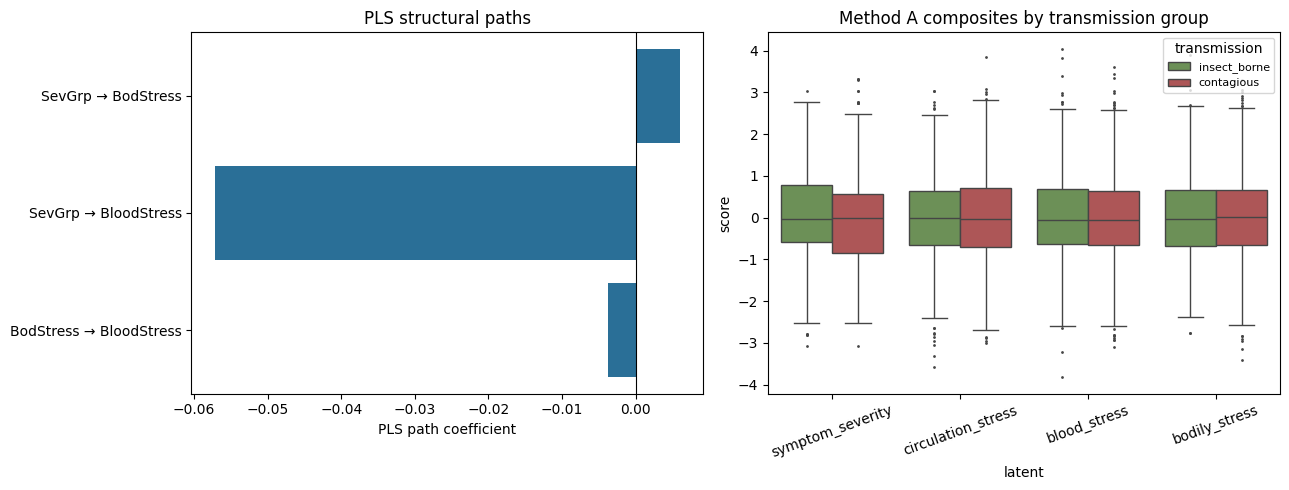

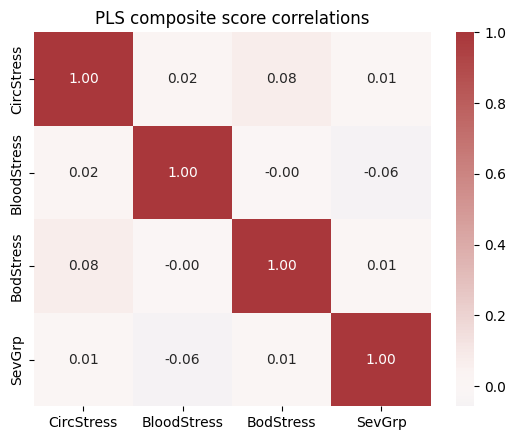

In [55]:
# Cell 16 · PLS-SEM visualizations — latents, structure, and transmission group

# --- 1) Bootstrapped structural paths
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

reg = pls_struct_paths.copy()
reg["label"] = reg["rval"] + " → " + reg["lval"]
colors = ["#2a6f97"] * len(reg)
axes[0].barh(reg["label"], reg["Est. Std"], color=colors)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_xlabel("PLS path coefficient")
axes[0].set_title("PLS structural paths")

# --- 2) Method A composites by transmission group (same as CB-SEM view)
plot_df = df_latent.copy()
melt = plot_df.melt(
    id_vars="transmission_group",
    value_vars=[
        SEVERITY_COL,
        "circulation_stress",
        "blood_stress",
        "bodily_stress",
    ],
    var_name="latent",
    value_name="score",
)
sns.boxplot(
    data=melt,
    x="latent",
    y="score",
    hue="transmission_group",
    hue_order=["insect_borne", "contagious"],
    ax=axes[1],
    fliersize=1,
    palette={"insect_borne": "#6a994e", "contagious": "#bc4749"},
)
axes[1].set_title("Method A composites by transmission group")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(title="transmission", loc="best", fontsize=8)

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "plssem_latent_transmission_visualization.png", dpi=150, bbox_inches="tight")
plt.show()

# --- 3) Correlation among PLS composite scores
pls_scores = named_matrix_to_frame(pls_fit.construct_scores)
score_corr = pls_scores.corr(numeric_only=True)
fig2, ax2 = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(score_corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax2)
ax2.set_title("PLS composite score correlations")
fig2.tight_layout()
plt.savefig(OUTPUT_DIR / "plssem_score_correlation.png", dpi=150)
plt.show()


In [56]:
# Cell 17 · Export PLS-SEM results
pls_export = df_analysis.copy()
pls_export = pls_export.join(named_matrix_to_frame(pls_fit.construct_scores))
for col in df_latent.columns:
    if col.endswith("_stress"):
        pls_export[col] = df_latent[col]

pls_boot_paths_table(pls_boot_summary).to_csv(OUTPUT_DIR / "plssem_bootstrapped_paths.csv")
pls_struct_paths.to_csv(OUTPUT_DIR / "plssem_structural_paths.csv", index=False)
pls_results.to_csv(OUTPUT_DIR / "plssem_structural_results.csv", index=False)
named_matrix_to_frame(pls_fit.r_squared).to_csv(OUTPUT_DIR / "plssem_r_squared.csv")
named_matrix_to_frame(pls_fit.outer_loadings).to_csv(OUTPUT_DIR / "plssem_outer_loadings.csv")
pls_export.to_csv(OUTPUT_DIR / "plssem_analysis_table.csv", index=False)

print("Wrote plssem_bootstrapped_paths.csv, plssem_structural_paths.csv, plssem_analysis_table.csv")


Wrote plssem_bootstrapped_paths.csv, plssem_structural_paths.csv, plssem_analysis_table.csv
